# Notebook 2 — Finding Candidate Pairs (Naive vs. Bonferroni vs. FDR)

**Goal of this notebook:**
1. Load the price data from Notebook 1 and split it into **Train (2015-2023)** and **Verify
   (2023-2025)** — pairs are selected using Train only, Verify stays untouched until Notebook 3
2. Run the cointegration test on all **190 possible pairs**, testing both regression orderings
   per pair (addresses part of the independence/dependence discussion below)
3. Compare three ways of deciding "is this pair significant": **naive** (p < 0.05, no
   adjustment), **Bonferroni** correction, and **Benjamini-Hochberg FDR** correction
4. Address the **independence issue**: daily stock data is a time series, so observations
   aren't independent the way a textbook t-test assumes. We show what this means visually and
   how each part of the analysis handles it.

Files are read directly from the shared Drive folder's `01_data_exploration` subfolder —
no manual upload needed, as long as Notebook 1 has been run at least once.

In [1]:
# Install packages not pre-installed on Colab
!pip install -q yfinance statsmodels

## 0. Google Drive setup

Same shared Drive folder as Notebook 1, by folder ID. This notebook reads Notebook 1's output
from the `01_data_exploration` subfolder, and saves its own output to `02_pair_selection`.

In [2]:
PARENT_FOLDER_ID = '1w9Q2nfcNhew6hzx8eQSCINReUy3OUwE1'
PREV_NOTEBOOK_FOLDER = '01_data_exploration'
THIS_NOTEBOOK_FOLDER = '02_pair_selection'

from google.colab import auth
auth.authenticate_user()

import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload, MediaIoBaseDownload
import io

creds, _ = google.auth.default()
drive_service = build('drive', 'v3', credentials=creds)


def get_or_create_subfolder(parent_id, name):
    """Find a subfolder by name under parent_id, creating it if it doesn't exist yet."""
    query = (f"'{parent_id}' in parents and name='{name}' "
             "and mimeType='application/vnd.google-apps.folder' and trashed=false")
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    files = results.get('files', [])
    if files:
        return files[0]['id']
    metadata = {'name': name, 'mimeType': 'application/vnd.google-apps.folder', 'parents': [parent_id]}
    folder = drive_service.files().create(body=metadata, fields='id', supportsAllDrives=True).execute()
    print(f"Created new Drive subfolder: {name}")
    return folder['id']


def upload_file(local_path, folder_id):
    """Upload (or overwrite) a local file into the given Drive folder."""
    filename = local_path.split('/')[-1]
    query = f"'{folder_id}' in parents and name='{filename}' and trashed=false"
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    existing = results.get('files', [])
    media = MediaFileUpload(local_path, resumable=True)
    if existing:
        drive_service.files().update(fileId=existing[0]['id'], media_body=media, supportsAllDrives=True).execute()
    else:
        metadata = {'name': filename, 'parents': [folder_id]}
        drive_service.files().create(body=metadata, media_body=media, fields='id', supportsAllDrives=True).execute()
    print(f"Uploaded {filename} to Drive.")


def download_file(filename, folder_id, local_path=None):
    """Download a file from the given Drive folder into the local Colab runtime."""
    local_path = local_path or filename
    query = f"'{folder_id}' in parents and name='{filename}' and trashed=false"
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    files = results.get('files', [])
    if not files:
        raise FileNotFoundError(f"{filename} not found in Drive folder.")
    request = drive_service.files().get_media(fileId=files[0]['id'], supportsAllDrives=True)
    fh = io.FileIO(local_path, 'wb')
    downloader = MediaIoBaseDownload(fh, request)
    done = False
    while not done:
        _, done = downloader.next_chunk()
    print(f"Downloaded {filename} from Drive.")
    return local_path


prev_folder_id = get_or_create_subfolder(PARENT_FOLDER_ID, PREV_NOTEBOOK_FOLDER)
this_folder_id = get_or_create_subfolder(PARENT_FOLDER_ID, THIS_NOTEBOOK_FOLDER)
print(f"Ready — reading from '{PREV_NOTEBOOK_FOLDER}', saving to '{THIS_NOTEBOOK_FOLDER}'.")

Ready — reading from '01_data_exploration', saving to '02_pair_selection'.


In [3]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint, acf
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_rows', 200)
plt.rcParams['figure.dpi'] = 110

## 1. Load prices (from Notebook 1's Drive folder, or re-download)

Tries to download `prices_full.csv` from the `01_data_exploration` Drive subfolder first
(faster, no re-download from Yahoo Finance needed). If it's not there, falls back to
downloading fresh from `yfinance`.

In [4]:
sectors = {
    'Retail':   ['WMT', 'COST', 'TGT', 'KR', 'DG', 'HD', 'LOW', 'TJX', 'ROST', 'DLTR'],
    'Payments': ['V', 'MA', 'AXP', 'PYPL', 'COF', 'GPN', 'XYZ', 'FIS', 'WU', 'EEFT'],
}
ticker_sector = {t: sec for sec, tickers in sectors.items() for t in tickers}
all_tickers = list(ticker_sector.keys())

try:
    download_file('prices_full.csv', prev_folder_id)
    prices = pd.read_csv('prices_full.csv', index_col=0, parse_dates=True)
    print("Loaded prices_full.csv from Drive (Notebook 1's folder).")
except FileNotFoundError:
    print("prices_full.csv not found in Drive — downloading fresh from yfinance.")
    import yfinance as yf
    raw_data = yf.download(all_tickers, start='2015-01-01', end='2025-01-01', auto_adjust=True)
    prices = raw_data['Close'].dropna()

print(f"Date range: {prices.index.min().date()} to {prices.index.max().date()} ({len(prices)} days)")

Downloaded prices_full.csv from Drive.
Loaded prices_full.csv from Drive (Notebook 1's folder).
Date range: 2015-11-19 to 2024-12-31 (2293 days)


## 2. Split into Train and Verify

Pairs are selected using **Train only**. Verify is held out completely until Notebook 3 — this
stops us from picking pairs because they happened to look good on the exact data we'll later
backtest the trading rule on.

In [5]:
train_start, train_end = '2015-01-01', '2022-12-31'
verify_start, verify_end = '2023-01-01', '2025-01-01'

prices_train = prices.loc[train_start:train_end]
prices_verify = prices.loc[verify_start:verify_end]

print(f"Train:  {prices_train.index.min().date()} to {prices_train.index.max().date()} ({len(prices_train)} days)")
print(f"Verify: {prices_verify.index.min().date()} to {prices_verify.index.max().date()} ({len(prices_verify)} days)")

Train:  2015-11-19 to 2022-12-30 (1791 days)
Verify: 2023-01-03 to 2024-12-31 (502 days)


## 3. The independence problem, shown visually

Standard hypothesis tests (plain t-tests, for example) assume each observation is unrelated to
the one before it. Daily stock prices violate this: today's price is built directly on
yesterday's. Before running 190 tests, let's see what this looks like.

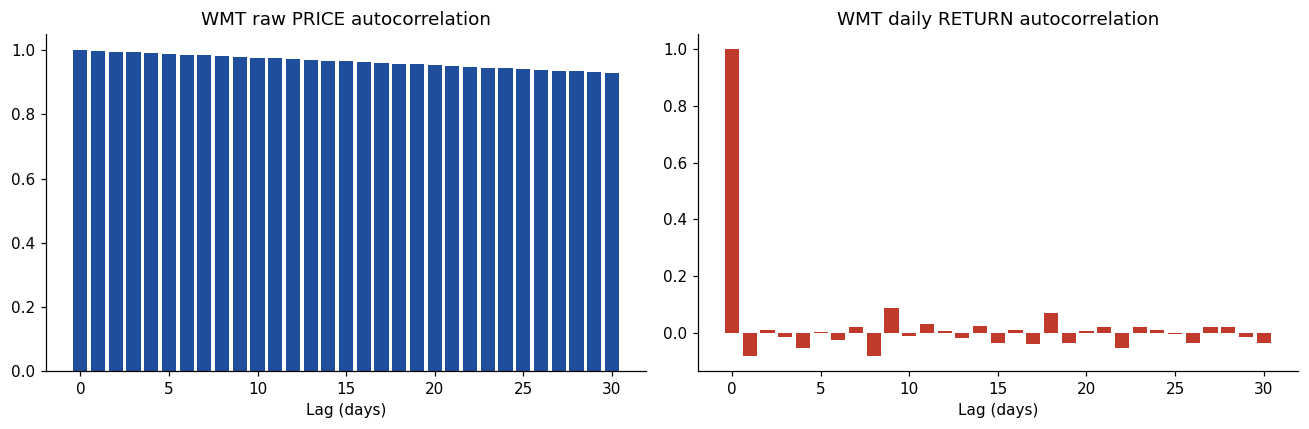

Left: raw prices stay highly correlated with their own past for many lags — this is
exactly the 'non-stationary' behavior cointegration is designed to work with.
Right: daily returns decay to near-zero autocorrelation much faster, but rarely hit
exactly zero — some dependence usually remains, which is why later notebooks still
use Newey-West standard errors and a block bootstrap rather than assuming full
independence.


In [6]:
# ACF of raw prices (should look highly persistent / slow-decaying — non-stationary)
# vs. ACF of daily RETURNS (should decay fast if returns are closer to independent)
example_ticker = 'WMT'
price_acf = acf(prices_train[example_ticker], nlags=30, fft=True)
returns_train = prices_train.pct_change().dropna()
return_acf = acf(returns_train[example_ticker], nlags=30, fft=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(len(price_acf)), price_acf, color='#1f4e9c')
axes[0].set_title(f'{example_ticker} raw PRICE autocorrelation')
axes[0].set_xlabel('Lag (days)')
axes[0].spines[['top', 'right']].set_visible(False)

axes[1].bar(range(len(return_acf)), return_acf, color='#c0392b')
axes[1].set_title(f'{example_ticker} daily RETURN autocorrelation')
axes[1].set_xlabel('Lag (days)')
axes[1].spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

print("Left: raw prices stay highly correlated with their own past for many lags — this is")
print("exactly the 'non-stationary' behavior cointegration is designed to work with.")
print("Right: daily returns decay to near-zero autocorrelation much faster, but rarely hit")
print("exactly zero — some dependence usually remains, which is why later notebooks still")
print("use Newey-West standard errors and a block bootstrap rather than assuming full")
print("independence.")

**How this notebook's test handles it:** the Augmented Dickey-Fuller test (used inside
`coint()` below) automatically selects enough lagged difference terms to absorb this
autocorrelation before testing — that's the "augmented" part of its name. We don't need to
manually fix independence for *this* test; it's built into the test's design. The remaining
independence concerns (trades overlapping in time, tests sharing stocks) are handled in
Notebooks 3-4 with Newey-West standard errors and a block bootstrap.

## 4. Test every pair for cointegration (Train period only)

For each pair, the Engle-Granger cointegration test regresses one stock's (log) price on the
other's and checks whether the leftover spread reverts to a stable average (ADF test on the
residuals). Because results can depend on **which stock is the dependent variable**, we test
both orderings and keep the **larger** (more conservative) p-value, as described in our
proposal.

In [7]:
results = []

for stock_a, stock_b in itertools.combinations(all_tickers, 2):
    series_a = np.log(prices_train[stock_a].values)
    series_b = np.log(prices_train[stock_b].values)

    # Test both orderings; keep the larger (more conservative) p-value
    _, p_ab, _ = coint(series_a, series_b)   # A as dependent variable
    _, p_ba, _ = coint(series_b, series_a)   # B as dependent variable
    p_value = max(p_ab, p_ba)

    results.append({
        'stock_1': stock_a,
        'stock_2': stock_b,
        'sector_1': ticker_sector[stock_a],
        'sector_2': ticker_sector[stock_b],
        'same_sector': ticker_sector[stock_a] == ticker_sector[stock_b],
        'p_value_AonB': p_ab,
        'p_value_BonA': p_ba,
        'p_value': p_value,
    })

results_df = pd.DataFrame(results).sort_values('p_value').reset_index(drop=True)
print(f"Total pairs tested: {len(results_df)}")
results_df.head(15)

Total pairs tested: 190


,stock_1,stock_2,sector_1,sector_2,same_sector,p_value_AonB,p_value_BonA,p_value
0,V,MA,Payments,Payments,True,0.000190,0.000203,0.000203
1,WMT,V,Retail,Payments,False,0.000614,0.000765,0.000765
2,WMT,MA,Retail,Payments,False,0.001601,0.002599,0.002599
3,WMT,HD,Retail,Retail,True,0.006675,0.010397,0.010397
4,COST,LOW,Retail,Retail,True,0.019456,0.015957,0.019456
5,ROST,V,Retail,Payments,False,0.008660,0.036259,0.036259
6,ROST,MA,Retail,Payments,False,0.009287,0.041956,0.041956
7,GPN,FIS,Payments,Payments,True,0.069707,0.062816,0.069707
8,COST,HD,Retail,Retail,True,0.075750,0.057546,0.075750
9,WMT,DG,Retail,Retail,True,0.062825,0.094113,0.094113


### Why order matters — a quick visual check

If the two orderings always gave identical p-values, testing both would be pointless. Here's
a scatter of p-value (A on B) vs. p-value (B on A) for all 190 pairs — points off the diagonal
show real disagreement between orderings.

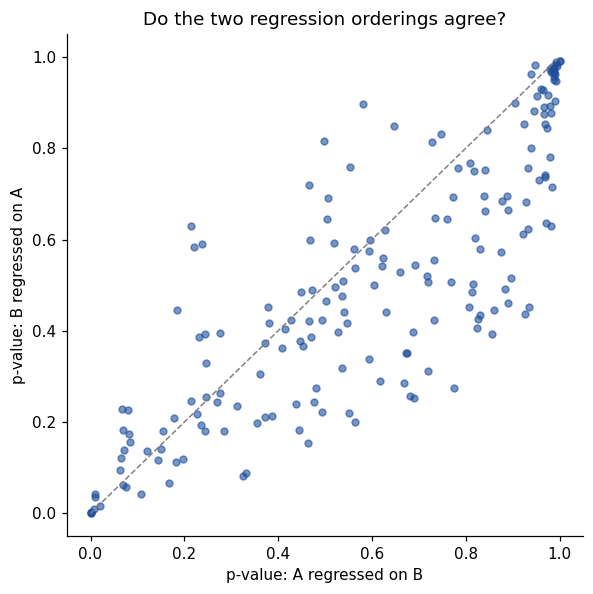

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(results_df['p_value_AonB'], results_df['p_value_BonA'], alpha=0.6, s=20, color='#1f4e9c')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('p-value: A regressed on B')
ax.set_ylabel('p-value: B regressed on A')
ax.set_title('Do the two regression orderings agree?')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 5. The distribution of all 190 p-values

If none of these pairs were truly cointegrated, p-values would be roughly uniformly spread
between 0 and 1. A pile-up near 0 suggests some pairs are genuinely cointegrated.

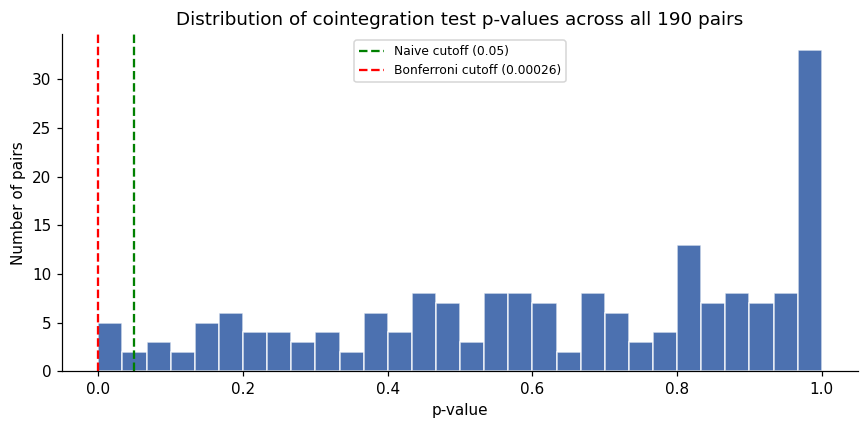

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(results_df['p_value'], bins=30, color='#1f4e9c', alpha=0.8, edgecolor='white')
ax.axvline(0.05, color='green', linestyle='--', label='Naive cutoff (0.05)')
n_tests = len(results_df)
bonferroni_threshold = 0.05 / n_tests
ax.axvline(bonferroni_threshold, color='red', linestyle='--', label=f'Bonferroni cutoff ({bonferroni_threshold:.5f})')
ax.set_xlabel('p-value')
ax.set_ylabel('Number of pairs')
ax.set_title('Distribution of cointegration test p-values across all 190 pairs')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 6. Naive vs. Bonferroni vs. FDR

- **Naive**: flag p < 0.05, no adjustment for having run 190 tests
- **Bonferroni**: flag p < 0.05 / 190 — controls the chance of even one false positive across
  all tests (this correction stays valid even when tests are dependent on each other, which
  matters since every stock appears in 19 different pairs)
- **Benjamini-Hochberg FDR**: controls the expected share of false discoveries among flagged
  pairs — less conservative, shown alongside as a second check

In [10]:
alpha = 0.05

results_df['naive_significant'] = results_df['p_value'] < alpha
results_df['bonferroni_significant'] = results_df['p_value'] < bonferroni_threshold

fdr_reject, fdr_pvals_corrected, _, _ = multipletests(results_df['p_value'], alpha=alpha, method='fdr_bh')
results_df['fdr_significant'] = fdr_reject
results_df['fdr_corrected_p'] = fdr_pvals_corrected

counts = {
    'Naive (p<0.05)': results_df['naive_significant'].sum(),
    'Bonferroni': results_df['bonferroni_significant'].sum(),
    'FDR (BH)': results_df['fdr_significant'].sum(),
}
for method, n in counts.items():
    print(f"{method:20s}: {n} of {n_tests} pairs significant")

Naive (p<0.05)      : 7 of 190 pairs significant
Bonferroni          : 1 of 190 pairs significant
FDR (BH)            : 1 of 190 pairs significant


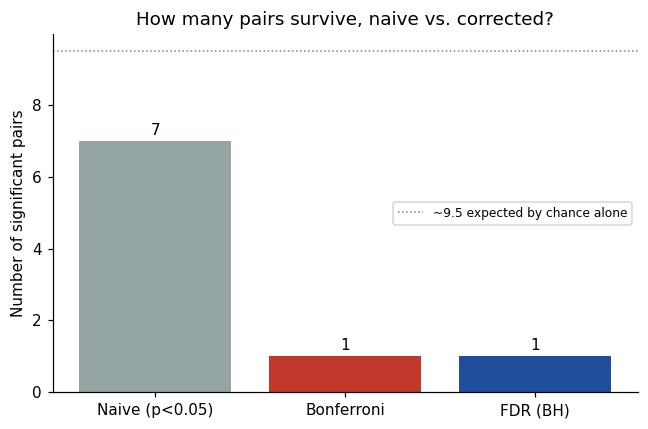

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.keys(), counts.values(), color=['#95a5a6', '#c0392b', '#1f4e9c'])
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{int(height)}', (bar.get_x() + bar.get_width()/2, height),
                textcoords='offset points', xytext=(0, 4), ha='center', fontsize=10)
ax.axhline(9.5, color='gray', linestyle=':', linewidth=1, label='~9.5 expected by chance alone')
ax.set_ylabel('Number of significant pairs')
ax.set_title('How many pairs survive, naive vs. corrected?')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 7. Final shortlists

In [12]:
final_pairs_bonferroni = results_df[results_df['bonferroni_significant']].sort_values('p_value')
final_pairs_fdr = results_df[results_df['fdr_significant']].sort_values('p_value')

print(f"Bonferroni shortlist ({len(final_pairs_bonferroni)} pairs):")
print(final_pairs_bonferroni[['stock_1', 'stock_2', 'p_value']].to_string(index=False))
print()
print(f"FDR shortlist ({len(final_pairs_fdr)} pairs):")
print(final_pairs_fdr[['stock_1', 'stock_2', 'p_value', 'fdr_corrected_p']].to_string(index=False))

Bonferroni shortlist (1 pairs):
stock_1 stock_2  p_value
      V      MA 0.000203

FDR shortlist (1 pairs):
stock_1 stock_2  p_value  fdr_corrected_p
      V      MA 0.000203         0.038537


## 8. Save results to Google Drive

Saved to the `02_pair_selection` Drive subfolder, so Notebook 3 can pull them directly.

In [13]:
results_df.to_csv('all_pairs_cointegration_results.csv', index=False)
final_pairs_bonferroni.to_csv('final_shortlisted_pairs_bonferroni.csv', index=False)
final_pairs_fdr.to_csv('final_shortlisted_pairs_fdr.csv', index=False)

prices_train.to_csv('prices_train.csv')
prices_verify.to_csv('prices_verify.csv')

output_files = [
    'all_pairs_cointegration_results.csv',
    'final_shortlisted_pairs_bonferroni.csv',
    'final_shortlisted_pairs_fdr.csv',
    'prices_train.csv',
    'prices_verify.csv',
]
for fname in output_files:
    upload_file(fname, this_folder_id)

print(f"Saved locally and uploaded to Drive ({THIS_NOTEBOOK_FOLDER}): {', '.join(output_files)}")

Uploaded all_pairs_cointegration_results.csv to Drive.
Uploaded final_shortlisted_pairs_bonferroni.csv to Drive.
Uploaded final_shortlisted_pairs_fdr.csv to Drive.
Uploaded prices_train.csv to Drive.
Uploaded prices_verify.csv to Drive.
Saved locally and uploaded to Drive (02_pair_selection): all_pairs_cointegration_results.csv, final_shortlisted_pairs_bonferroni.csv, final_shortlisted_pairs_fdr.csv, prices_train.csv, prices_verify.csv


## Next notebook

**Notebook 3** builds the actual trading rule (spread + rolling z-score, entry/exit thresholds)
for the Bonferroni shortlist, and backtests it on the untouched Verify period (2023-2025).